# 02 – Preprocessing and baseline models

## Load and clean

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Fix TotalCharges: blanks -> NaN -> 0 (these are tenure = 0 customers, not yet billed)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is just a label, it has no predictive meaning
df = df.drop(columns=["customerID"])

# Target as 0/1
df["Churn"] = (df["Churn"] == "Yes").astype(int)

print(df.shape, "| missing values:", df.isnull().sum().sum())

(7043, 20) | missing values: 0


## Train/test split

In [7]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 0.265 | test: 0.265


## Preprocessing pipeline

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]  # includes SeniorCitizen (already 0/1) and all text columns

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

## Evaluation helper

In [9]:
results = []

def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    results.append(row)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"])
    plt.title(name)
    plt.show()
    return row

## Baseline models

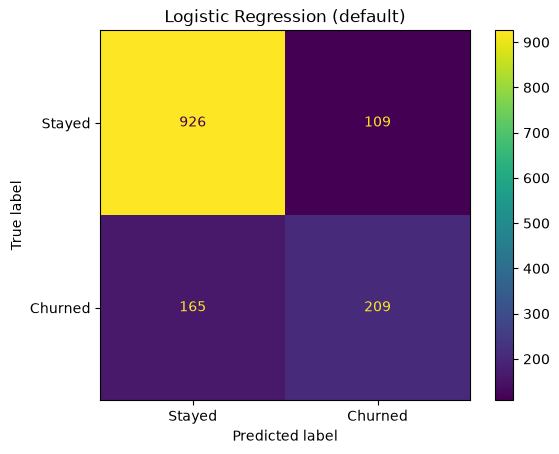

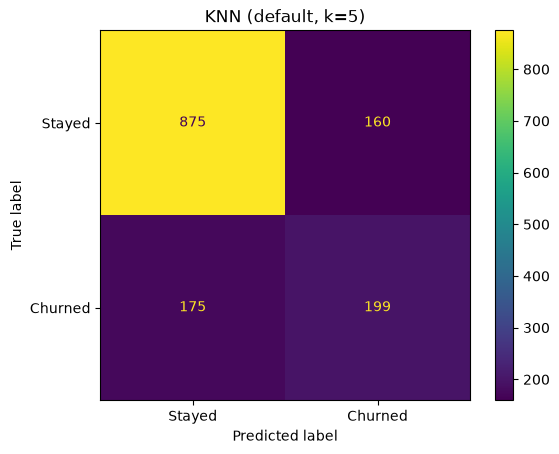

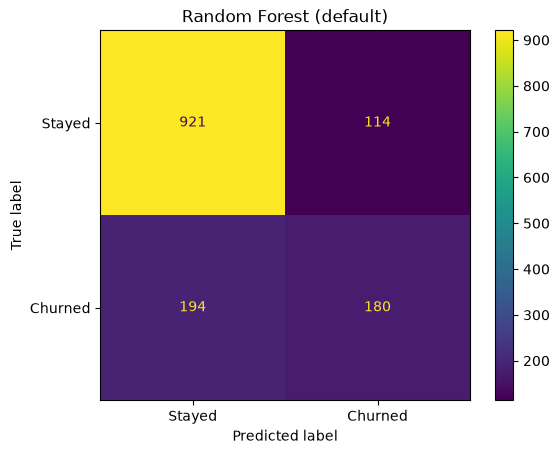

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (default),0.806,0.657,0.559,0.604,0.842
1,"KNN (default, k=5)",0.762,0.554,0.532,0.543,0.777
2,Random Forest (default),0.781,0.612,0.481,0.539,0.821


In [10]:
models = {
    "Logistic Regression (default)": LogisticRegression(max_iter=1000),
    "KNN (default, k=5)": KNeighborsClassifier(),
    "Random Forest (default)": RandomForestClassifier(random_state=42),
}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    evaluate(name, pipe)

pd.DataFrame(results).round(3)

## Baseline results (default hyperparameters)

- Logistic Regression performed best overall (accuracy 0.806, F1 0.604, ROC-AUC 0.842).
- KNN (k=5) had the weakest ranking ability (ROC-AUC 0.777).
- Random Forest reached ROC-AUC 0.821 but had the lowest recall (0.481), meaning it missed more than half of the churners.
- All three models have recall between 0.48 and 0.56 because the target is imbalanced (26.5% churn). Accuracy alone overstates performance, since predicting "stayed" for everyone would score about 73.5%.
- Next step: hyperparameter tuning and class weighting to improve recall and F1.